# One policy, the whole knob: weight-conditioned DPC on the two-tank

This notebook trains, from scratch, the two-tank controllers of the paper and reproduces its two-tank
**regret-vs-optimum** figure:

* a **generalist**: one DPC policy that takes the objective weight $w_1$ as an input and is trained
  over four decades of it, $w_1 \in [0.01, 100]$;
* three **specialists**: standard DPC, one policy per fixed weight, $w_1 \in \{0.01, 1, 100\}$;
* the **MPC** that the policies target (nonlinear MPC, horizon 80 steps), all scored against
* the **optimum** of each 80-step test episode.

> **This is a reduced-scale reproduction.** The method is the paper's, line for line: the same plant,
> loss, architecture, weight encoding, loss normalizer, learning-rate schedule, checkpoint rule and
> evaluation. The paper's training code produces bit-identical dev scores on a short run.
> The *budget* is not the paper's. Here every run trains for about 2,000 iterations instead of 36,000, with one seed
> instead of five. The curves therefore have the paper's shape but sit above the paper's numbers. The
> full-scale figures are in [`figures/`](figures/) (this one is `figures/regret_opt.png`, middle panel).
> Set `RUN = "paper"` below to train at the paper's budget (about 70 CPU-minutes per run).

![pipeline](figures/pipeline.png)

*Training: weights are sampled per window, encoded and fed to the policy alongside the state; the closed
loop is rolled through the known plant; the weighted cost is normalized per weight bin and
back-propagated through the dynamics.*

In [1]:
import sys, time, inspect
sys.path.insert(0, "src")

import numpy as np
import torch
import matplotlib.pyplot as plt
from IPython.display import Image, display

from amortdpc import train as T
from amortdpc.twotank import TwoTank, eval_set, simulate, steady_optimum, EPISODE
from amortdpc.policy import actor
from amortdpc.evaluate import sweep, regret, references

torch.set_num_threads(1)
T_START = time.time()
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "legend.frameon": False})
C_GEN, C_SPEC, C_REF = "#6a3d9a", "#b2182b", "#1a1a1a"      # the paper's colors

## 1. The problem

Two tanks in cascade: a pump $p$ fills tank 1, and a valve $v$ splits the flow between the tanks; tank 1 drains
into tank 2. Inputs are bounded, $p, v \in [0, 0.5]$; one control step is 5 s. Each episode holds a pair of
level references $(r_1, r_2)$ for 80 steps (400 s).

At steady state the reachable levels satisfy $h_2/4 \le h_1 \le h_2$, so **when $r_1 > r_2$ (half the
episodes) both references cannot be met**. The objective decides the compromise:

$$J(w) = \frac{1}{N}\sum_{k} \Big[(h_{2,k+1}-r_2)^2 \;+\; w_1\,(h_{1,k+1}-r_1)^2 \;+\; 0.1\,\|u_k-u_{k-1}\|^2\Big]$$

$w_1$ is the knob. The steady compromise it selects moves across the whole reachable set as $w_1$ sweeps four decades:

In [2]:
r1, r2 = 0.8, 0.4          # an infeasible pair: tank 1 asked to sit above tank 2 (the best compromise has h1 = h2)
for w1 in [0.01, 0.1, 1, 10, 100]:
    h1, h2 = steady_optimum(r1, r2, w1)
    print(f"w1 = {w1:>6}:  steady levels h1 = {h1:.3f}, h2 = {h2:.3f}")

w1 =   0.01:  steady levels h1 = 0.404, h2 = 0.404
w1 =    0.1:  steady levels h1 = 0.436, h2 = 0.436
w1 =      1:  steady levels h1 = 0.600, h2 = 0.600
w1 =     10:  steady levels h1 = 0.764, h2 = 0.764
w1 =    100:  steady levels h1 = 0.796, h2 = 0.796


## 2. The method: what changes from standard DPC

Standard DPC trains a policy $u_k = \pi_\theta(o_k)$ by rolling the closed loop through the differentiable plant
and descending the objective at **one fixed $w$**. Here:

1. **The weight is a policy input.** $u_k = \pi_\theta\big([o_k,\ \phi(w),\ \psi(\tau_k)]\big)$, plain concatenation into
   a 3×64 MLP. $\phi(w)$ is a shifted log of $w$, scaled to $[-1, 1]$.
2. **The weight is sampled per training window,** log-uniform over the box, and applied per sample in the loss.
3. **The loss is normalized per weight bin:** $J(w)/n(w)$, where $n(w)$ is a running mean of $J$ in $w$'s bin
   (12 log bins). Without it, the high-cost end of the knob dominates the gradient.

$\psi(\tau_k)$ is the time-to-go, $\tau_k = N - k$, from companion work. Every controller here, specialists included,
has it, and every policy is deployed at $\tau = N = 80$, so it targets the 80-step MPC. A **specialist** is the same code with $w$ pinned.

The whole training objective is this function in [`src/amortdpc/train.py`](src/amortdpc/train.py):

In [3]:
print(inspect.getsource(T.objective))

def objective(case, ws, policy, sc, w, N, normalize=True, update=False):
    """Per-sample J(w) / n(w) over an N-step closed-loop window, tau counting down N, N-1, ..., 1."""
    _, _, T = simulate(case, actor(case, policy, ws.encode(w), tau=lambda k: N - k), sc, N)
    J = weighted(T, ws.full(w), case.terms)
    if update and ws.norm == "running":
        ws.update_running(w, J)
    return (J / ws.n(w) if normalize else J), T



## 3. The budget

`T.PAPER` is the paper's two-tank configuration. The tutorial keeps all of it except the length of the run.
The generalist trains on the box padded by one normalizer bin at each end (`pad=1`, the paper's generalist).

| `RUN` | per run | wall time, 4 runs in parallel |
|:--|:--|:--|
| `"fast"` (default) | batch 512 × 2,000 iterations | about 3–5 min on a 4-core laptop |
| `"longer"` | batch 1024 × 6,000 iterations | about 12–20 min |
| `"paper"` | batch 1024 × 36,000 iterations | about 70 min (the paper used 5 seeds) |

In [4]:
RUN = "fast"
BUDGETS = {"fast":   dict(batch=512,  iters=2000,  warmup_iters=50,  dev_batch=1024),
           "longer": dict(batch=1024, iters=6000,  warmup_iters=200, dev_batch=2048),
           "paper":  dict()}                                  # = T.PAPER
cfg = BUDGETS[RUN]
SEED = 0
SPEC_W = [0.01, 1.0, 100.0]                                   # the paper's specialists
print({**T.PAPER, **cfg})

{'N': 80, 'batch': 512, 'iters': 2000, 'lr': 0.005, 'lr_final': 5e-05, 'warmup_frac': 0.05, 'warmup_iters': 50, 'dev_batch': 1024, 'eval_every': 100, 'grad_clip': 1.0, 'rewind_tol': 1.0, 'rewind_after': 2, 'rewind_max': 10, 'lo': 0.01, 'hi': 100.0, 'smooth': 0.1, 'norm': 'running', 'pad': 1, 'hidden': 64, 'layers': 3}


## 4. Train the generalist and the three specialists

The four runs are independent, so they train in parallel, one process and one thread each (`train_many`).
Each run keeps its best checkpoint on a fixed dev set. Run order and timing depend on your machine.

In [5]:
t0 = time.time()
runs, logs = {}, {}
for spec, policy, ws, log in T.train_many(cfg, [None] + SPEC_W, seed=SEED):
    name = "generalist" if spec is None else f"specialist w1={spec:g}"
    runs[spec], logs[name] = (policy, ws), log
    print(f"{time.time() - t0:6.0f} s  finished {name:24s} best dev score {log[-1]['best']:.4f}")
TRAIN_SEC = time.time() - t0

   182 s  finished specialist w1=100        best dev score -1.4438
   182 s  finished generalist               best dev score -3.6794
   182 s  finished specialist w1=1          best dev score -3.4547


   183 s  finished specialist w1=0.01       best dev score -5.5725


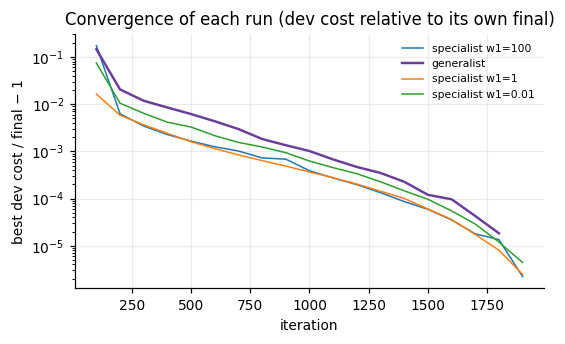

In [6]:
fig, ax = plt.subplots(figsize=(5.5, 3))
for name, log in logs.items():
    it = [r["it"] for r in log]
    best = np.array([r["best"] for r in log])
    gap = np.exp(best - best[-1]) - 1
    ax.plot(np.array(it)[gap > 0], gap[gap > 0], label=name,
            color=C_GEN if name == "generalist" else None, lw=1.6 if name == "generalist" else 1)
ax.set(yscale="log", xlabel="iteration", ylabel="best dev cost / final − 1",
       title="Convergence of each run (dev cost relative to its own final)")
ax.legend(fontsize=7); plt.show()

This curve shows when each run's cosine schedule has annealed (each against its own final). It does not show
how close the run is to the paper's 36,000-iteration runs. Section 6 measures that.

## 5. The references: MPC and the episode optimum

Both references solve the same optimal control problem on the same discrete plant with CasADi + IPOPT
([`src/amortdpc/mpc.py`](src/amortdpc/mpc.py)):

* **MPC**, horizon $H = 80$, re-solved at every step (receding horizon). It is what a policy deployed at $\tau = 80$ targets.
* **The optimum**: one NLP over the whole 80-step episode. The plant is deterministic and known, so the best
  closed loop is the best open-loop plan. It can exploit the episode's end, which no 80-step receding-horizon
  controller sees, so even the MPC has a positive regret against it.

Computing both for 25 weights × 40 episodes takes about an hour of CPU time, so the paper's values ship in
`data/twotank_references.npz`, and `scripts/make_references.py` regenerates them. The next cell re-solves a few of them
live, to show the shipped numbers come from this code.

In [7]:
R = references("data/twotank_references.npz")
W1 = R["w1"]                                       # 25 weights, log-spaced on [0.01, 100]
print("episodes:", R["opt"].shape[1], "| weights:", len(W1))

try:
    from amortdpc.mpc import mpc_episode, optimum
    iw = int(np.argmin(abs(np.log(W1))))            # w1 = 1
    for i in (0, 1):
        t = time.time(); J_mpc, U_mpc, solve = mpc_episode(W1[iw], i); t_mpc = time.time() - t
        t = time.time(); J_opt, _ = optimum(W1[iw], i, guesses=[U_mpc], n_random=0); t_opt = time.time() - t
        print(f"episode {i}, w1 = 1:  MPC {J_mpc:.6g} (shipped {R['mpc'][iw, i]:.6g}; {t_mpc:.1f} s, "
              f"{1000 * solve:.0f} ms per solve)   optimum {J_opt:.6g} (shipped {R['opt'][iw, i]:.6g}; {t_opt:.1f} s)")
except ImportError:
    print("casadi is not installed: skipping the live check (the shipped references are used below).")

episodes: 40 | weights: 25


episode 0, w1 = 1:  MPC 0.00189819 (shipped 0.00189819; 1.6 s, 14 ms per solve)   optimum 0.00189819 (shipped 0.00189819; 0.5 s)


episode 1, w1 = 1:  MPC 0.00327665 (shipped 0.00327665; 1.7 s, 16 ms per solve)   optimum 0.00326354 (shipped 0.00326354; 0.5 s)


## 6. Score every controller in closed loop

Every controller runs on the 40 held-out episodes, on the true plant, with the true weights. The generalist runs at
all 25 weights at once (one batched rollout); each specialist runs at its own weight. Regret at $w$ is
$\bar J_{\text{ctrl}}(w) / \bar J_{\text{opt}}(w) - 1$, with $\bar J$ the mean over the 40 episodes.

In [8]:
gen_policy, gen_ws = runs[None]
J_gen = sweep(gen_policy, gen_ws, W1)                                 # [25, 40]
reg_gen_opt, reg_gen_mpc = regret(J_gen, R["opt"]), regret(J_gen, R["mpc"])
reg_mpc_opt = regret(R["mpc"], R["opt"])

spec_rows = []
for w in SPEC_W:
    pol, ws = runs[w]
    iw = int(np.argmin(abs(np.log(W1 / w))))
    J = sweep(pol, ws, [W1[iw]])
    spec_rows.append((w, regret(J, R["opt"][iw:iw + 1])[0], regret(J, R["mpc"][iw:iw + 1])[0],
                      reg_gen_mpc[iw], reg_mpc_opt[iw]))

print(f"generalist vs MPC over the knob: mean {100 * reg_gen_mpc.mean():.3f}%, worst {100 * reg_gen_mpc.max():.3f}%")
print(f"\n{'w1':>6} | {'specialist vs MPC':>17} | {'generalist vs MPC':>17} | {'MPC vs optimum':>14}")
for w, ro, rm, gm, mo in spec_rows:
    print(f"{w:>6g} | {100 * rm:16.3f}% | {100 * gm:16.3f}% | {100 * mo:13.3f}%")

generalist vs MPC over the knob: mean 0.316%, worst 0.728%

    w1 | specialist vs MPC | generalist vs MPC | MPC vs optimum
  0.01 |            0.316% |            0.728% |         0.055%
     1 |            0.119% |            0.158% |         1.637%
   100 |            0.133% |            0.222% |         0.012%


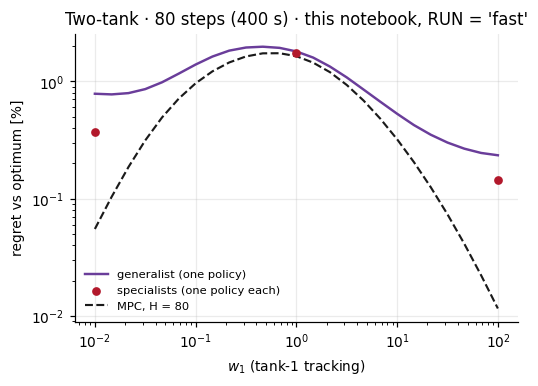

In [9]:
fig, ax = plt.subplots(figsize=(5.2, 3.4))
ax.plot(W1, 100 * reg_gen_opt, color=C_GEN, lw=1.6, label="generalist (one policy)")
ax.scatter([r[0] for r in spec_rows], [100 * r[1] for r in spec_rows], color=C_SPEC, s=22, zorder=3,
           label="specialists (one policy each)")
ax.plot(W1, 100 * reg_mpc_opt, color=C_REF, lw=1.4, ls="--", label="MPC, H = 80")
ax.set(xscale="log", yscale="log", xlabel=r"$w_1$ (tank-1 tracking)", ylabel="regret vs optimum [%]",
       title=f"Two-tank · 80 steps (400 s) · this notebook, RUN = {RUN!r}")
ax.legend(fontsize=7.5)
plt.show()

For comparison, the paper's figure (middle panel; 5 seeds at 36,000 iterations, shading: min–max over seeds):

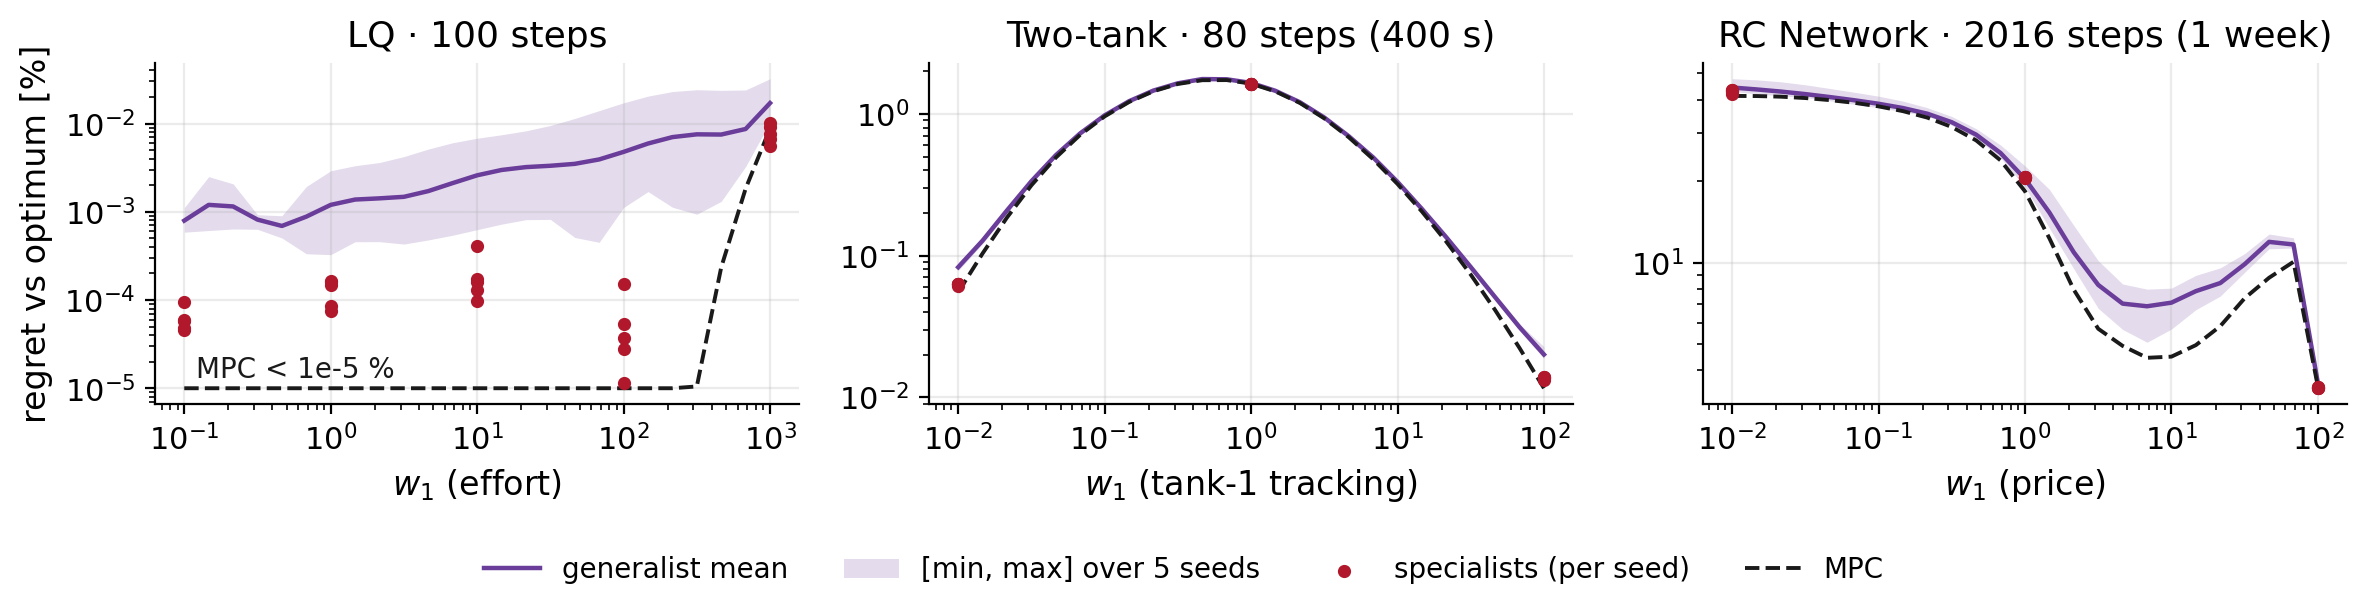

In [10]:
display(Image("figures/regret_opt.png", width=900))

**What to look for.** The hump is the MPC's own gap to the optimum: an 80-step receding-horizon controller cannot exploit
the end of an 80-step episode, and that matters most in the middle of the knob. The policies target that MPC, so they
inherit its hump. Their distance above the dashed line is training error. In the paper that distance is a few hundredths
of a percent, and the generalist sits on the specialists at their weights. At this notebook's budget the distance is
larger, and a longer `RUN` closes it.

## 7. One policy, the whole knob

The same trained generalist on one infeasible episode, with only its weight input changed:

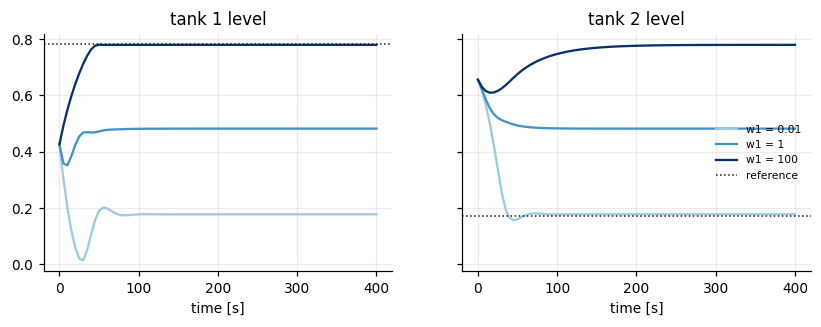

In [11]:
sc = eval_set()
i = int(np.argmax((sc.exo["r"][:, 0, 0] - sc.exo["r"][:, 0, 1]).numpy()))     # the most infeasible pair
one = sc.index(slice(i, i + 1))
fig, axs = plt.subplots(1, 2, figsize=(9, 2.8), sharey=True)
t = 5 * np.arange(EPISODE + 1)
for w, c in zip([0.01, 1.0, 100.0], ["#9ecae1", "#4292c6", "#08306b"]):
    with torch.no_grad():
        X, U, _ = simulate(TwoTank(), actor(TwoTank(), gen_policy, gen_ws.encode(torch.tensor([w]))), one, EPISODE)
    for k, ax in enumerate(axs):
        ax.plot(t, X[0, :, k], color=c, label=f"w1 = {w:g}")
for k, ax in enumerate(axs):
    ax.axhline(one.exo["r"][0, 0, k], color=C_REF, ls=":", lw=1, label="reference")
    ax.set(xlabel="time [s]", title=f"tank {k + 1} level")
axs[1].legend(fontsize=7, loc="center right"); plt.show()

## 8. Using this on your own system

Everything system-specific is in [`src/amortdpc/twotank.py`](src/amortdpc/twotank.py). To condition DPC on the weights
of your own problem:

1. **Write the plant as a differentiable step** `step(x, u, sc, k)` in torch, and **the objective as named terms**
   `stage(...) -> {name: [B]}`, with no weights inside. The weights multiply the terms outside (`weighted`).
2. **Pick the knob(s) and the box.** Choose which terms get a sampled weight and over what range. Log-uniform sampling suits
   weights spanning decades. Encode with $\phi(w)$ (`WeightSpace.encode`).
3. **Concatenate $\phi(w)$ to the policy input** and sample a fresh $w$ per training window (`train.objective`).
4. **Normalize the loss per weight bin** (`WeightSpace.n`, `norm="running"`). Set `norm="none"` to see what happens without it.
5. **Score in closed loop against a reference at the same weights** (MPC, or an optimum where one exists), never by training loss.

The paper does the same for a linear-quadratic system and a building thermal model, and in two dimensions
(a second knob on the move penalty); see `figures/`.

In [12]:
print(f"training (4 runs in parallel): {TRAIN_SEC / 60:.1f} min   whole notebook: {(time.time() - T_START) / 60:.1f} min")

training (4 runs in parallel): 3.0 min   whole notebook: 3.1 min
